---
title: "Noninertial Frames — Level 2"
short_title: "08 Noninertial Frames"
numbering:
  heading_2: true
  equation: true
---

# Noninertial Frames

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | — (a gap in Tipler & Mosca) | Start at Level 2 |
| **2** | **Taylor, ch. 9** | **Derive centrifugal and Coriolis forces; tides, deflection of falling bodies, Foucault's pendulum** |
| 3 | Goldstein, ch. 4 | Rotation matrices, Euler angles, and the general kinematics of rotating coordinates |

The new skill at this level: writing Newton's law in a frame that accelerates or rotates, by adding the fictitious forces it requires

Math for this topic: M6, linear algebra (rotations and the angular-velocity matrix).
:::

Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp, quad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
g = 9.81  # m/s^2

## Linearly Accelerating Frames

Let a frame $\mathcal{S}'$ accelerate with acceleration $\mathbf{A}(t)$ relative to an inertial frame $\mathcal{S}$, without rotating. Positions are related by $\mathbf{r} = \mathbf{r}' + \mathbf{R}(t)$, so accelerations satisfy $\ddot{\mathbf{r}} = \ddot{\mathbf{r}}' + \mathbf{A}$. Newton's law in $\mathcal{S}$, rewritten in $\mathcal{S}'$, becomes

$$
m\ddot{\mathbf{r}}' = \mathbf{F} - m\mathbf{A} .
$$ (eq-accel-frame)

The extra term $-m\mathbf{A}$ is an **inertial (fictitious) force**. It is proportional to mass, exactly like gravity, which is why you cannot tell from inside a sealed box whether it is accelerating or sitting in a gravitational field.

### Tides

The Earth falls freely toward the Moon. In the Earth's (accelerating) frame, a mass at position $\mathbf{r}$ relative to Earth's center feels the Moon's pull **minus** the pull at Earth's center (the $-m\mathbf{A}$ term):

$$
\mathbf{F}_{\text{tidal}} = -GM_{\text{m}}m\left(\frac{\hat{\mathbf{d}}}{d^2} - \frac{\hat{\mathbf{d}}_0}{d_0^2}\right) ,
$$

where $\mathbf{d}$ points from the Moon to the mass and $\mathbf{d}_0$ from the Moon to Earth's center. On the near side the Moon pulls harder than average, and on the far side weaker, so the oceans bulge **on both sides**. Two bulges explain two high tides a day. Expanding for $r\ll d_0$, the tidal acceleration along the Earth–Moon line is about $2GM_{\text{m}}r/d_0^3$.

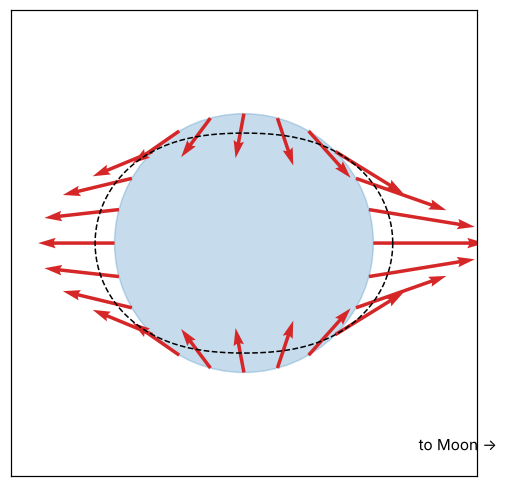

In [2]:
#| label: fig-tides
#| caption: Tidal acceleration around the Earth from the Moon (to the right), in the Earth's freely falling frame. The field stretches the Earth along the Earth–Moon line and squeezes it across, giving two bulges.
th = np.linspace(0, 2 * np.pi, 24, endpoint=False)
x, y = np.cos(th), np.sin(th)
d0 = 8.0                                   # Moon distance in Earth radii (exaggeratedly close)
dx, dy = x - d0, y                         # from the Moon to each surface point
d = np.hypot(dx, dy)
ax_ = -dx / d**3 - 1 / d0**2              # Moon's pull minus the pull at Earth's center (which is +x, magnitude 1/d0^2)
ay_ = -dy / d**3
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.add_patch(plt.Circle((0, 0), 1, color="tab:blue", alpha=0.25))
ax.quiver(x, y, ax_, ay_, color="tab:red", scale=0.02)
tt = np.linspace(0, 2 * np.pi, 200)
ax.plot((1 + 0.15 * np.cos(2 * tt)) * np.cos(tt), (1 + 0.15 * np.cos(2 * tt)) * np.sin(tt), "k--", lw=1)
ax.annotate("to Moon →", (1.35, -1.6))
ax.set_xlim(-1.8, 1.8); ax.set_ylim(-1.8, 1.8); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
plt.show()

## Rotating Frames

Now let $\mathcal{S}$ rotate with angular velocity $\boldsymbol\Omega$ relative to an inertial frame $\mathcal{S}_0$ with the same origin. Any vector $\mathbf{Q}$ has a rate of change as seen in each frame. The basis vectors of $\mathcal{S}$ are carried along by the rotation, each changing as $\dot{\mathbf{e}}_i = \boldsymbol\Omega\times\mathbf{e}_i$ (M6). So

$$
\left(\frac{d\mathbf{Q}}{dt}\right)_{\mathcal{S}_0} = \left(\frac{d\mathbf{Q}}{dt}\right)_{\mathcal{S}} + \boldsymbol\Omega\times\mathbf{Q} .
$$ (eq-rotating-derivative)

Apply this twice to the position vector (for constant $\boldsymbol\Omega$). The inertial acceleration is

$$
\ddot{\mathbf{r}}_{\mathcal{S}_0} = \ddot{\mathbf{r}} + 2\boldsymbol\Omega\times\dot{\mathbf{r}} + \boldsymbol\Omega\times(\boldsymbol\Omega\times\mathbf{r}) ,
$$

where unadorned dots are now rates in the rotating frame. Setting $m\ddot{\mathbf{r}}_{\mathcal{S}_0} = \mathbf{F}$ and solving for the rotating-frame acceleration:

$$
m\ddot{\mathbf{r}} = \mathbf{F} + \underbrace{2m\,\dot{\mathbf{r}}\times\boldsymbol\Omega}_{\text{Coriolis}} + \underbrace{m(\boldsymbol\Omega\times\mathbf{r})\times\boldsymbol\Omega}_{\text{centrifugal}} .
$$ (eq-rotating-newton)

- The **centrifugal force** points directly away from the rotation axis, with magnitude $m\Omega^2\rho$ ($\rho$ = distance from the axis). It depends only on position.
- The **Coriolis force** is perpendicular to the velocity in the rotating frame, so it does no work. It deflects moving objects, to the right in the Northern Hemisphere.

In [3]:
# Check the rotating-frame acceleration with sympy: express inertial coordinates of a point
# rotating-frame coordinates (x, y, z) in a frame turning at Omega about z.
t, W = sp.symbols("t Omega", real=True)
x, y, z = [sp.Function(n)(t) for n in "xyz"]
Rz = sp.Matrix([[sp.cos(W * t), -sp.sin(W * t), 0], [sp.sin(W * t), sp.cos(W * t), 0], [0, 0, 1]])
r_rot = sp.Matrix([x, y, z])
a_inertial = (Rz * r_rot).diff(t, 2)
a_in_rot_axes = sp.simplify(Rz.T * a_inertial)          # inertial acceleration, components on rotating axes
Om = sp.Matrix([0, 0, W])
predicted = r_rot.diff(t, 2) + 2 * Om.cross(r_rot.diff(t)) + Om.cross(Om.cross(r_rot))
print("difference:", sp.simplify(a_in_rot_axes - predicted).T)

difference: Matrix([[0, 0, 0]])


## On the Rotating Earth

The Earth turns with $\Omega = 2\pi/(\text{sidereal day})\approx7.29\times10^{-5}$ rad/s.

### Effective gravity

The centrifugal force is so steady that it is folded into "gravity": $\mathbf{g}_{\text{eff}} = \mathbf{g}_0 + (\boldsymbol\Omega\times\mathbf{r})\times\boldsymbol\Omega$. It reduces $g$ by $\Omega^2R\approx0.034\ \text{m/s}^2$ at the equator (zero at the poles), and tilts plumb lines away from the true vertical by up to about $0.1^\circ$ at mid-latitudes. The Earth's equatorial bulge is the oceans and rock settling into that effective field.

### Coriolis deflection

At latitude $\lambda$, the local vertical component of $\boldsymbol\Omega$ is $\Omega\sin\lambda$. For horizontal motion, the horizontal part of the Coriolis acceleration is $2\Omega\sin\lambda\,v$, to the right of the motion in the north (left in the south) and zero at the equator. It is tiny for a thrown ball but dominates large-scale weather. Air flowing toward a low-pressure center is deflected into a counterclockwise spiral in the Northern Hemisphere, which is why hurricanes rotate that way.

### A falling object lands east

Drop an object from height $h$ at the equator. As it falls, its velocity is downward, and $2m\dot{\mathbf{r}}\times\boldsymbol\Omega$ points **east**. To first order in $\Omega$, the eastward displacement after falling time $t$ is

$$
\Delta x = \tfrac13\,\Omega g t^3\cos\lambda .
$$

The physical reason: the top of the tower is farther from Earth's axis than the base, so it moves east slightly faster, and the object keeps that extra eastward speed as it falls.

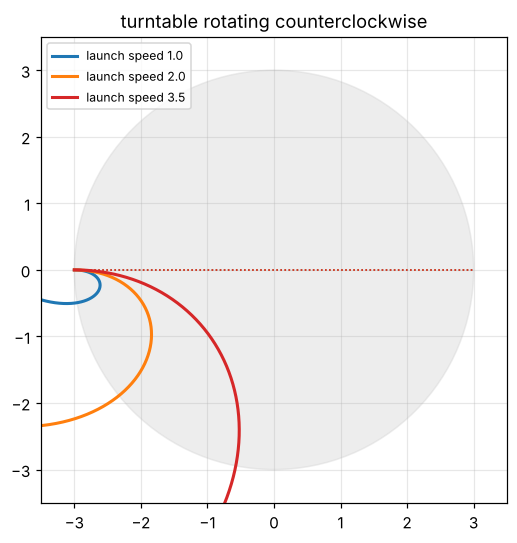

In [4]:
#| label: fig-coriolis-throw
#| caption: A puck slid across a frictionless rotating turntable, seen in the rotating frame. In the inertial frame it moves in a straight line; in the rotating frame, Coriolis and centrifugal forces curve its path.
Om = 0.6
def rhs(s, u):
    x, y, vx, vy = u
    ax_ = 2 * Om * vy + Om**2 * x        # Coriolis + centrifugal for Omega along +z
    ay_ = -2 * Om * vx + Om**2 * y
    return [vx, vy, ax_, ay_]
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.add_patch(plt.Circle((0, 0), 3, color="lightgray", alpha=0.4))
for v0, c in [(1.0, "tab:blue"), (2.0, "tab:orange"), (3.5, "tab:red")]:
    T = 6 / v0
    sol = solve_ivp(rhs, (0, T), [-3, 0, v0, 0], max_step=0.01)
    ax.plot(sol.y[0], sol.y[1], color=c, lw=2, label=f"launch speed {v0}")
    ax.plot([-3, 3], [0, 0], color=c, ls=":", lw=1)
ax.set_aspect("equal"); ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5)
ax.set_title("turntable rotating counterclockwise")
ax.legend(fontsize=8, loc="upper left"); plt.show()

## Foucault's Pendulum

A long pendulum swinging at latitude $\lambda$ is a slow demonstration of the Earth's rotation. For small swings, keep only the horizontal components of the Coriolis force, which come from the vertical part of $\boldsymbol\Omega$, $\Omega_z = \Omega\sin\lambda$:

$$
\ddot x = -\omega_0^2x + 2\Omega_z\dot y, \qquad \ddot y = -\omega_0^2y - 2\Omega_z\dot x .
$$

Combine them into the complex variable $\eta = x + iy$ (the M1 trick):

$$
\ddot\eta + 2i\Omega_z\dot\eta + \omega_0^2\eta = 0 .
$$

Because $\Omega_z\ll\omega_0$, the solution is approximately $\eta = e^{-i\Omega_zt}\big(C_1e^{i\omega_0t} + C_2e^{-i\omega_0t}\big)$: an ordinary pendulum swing (in the bracket) whose plane rotates clockwise at angular rate $\Omega\sin\lambda$. One full turn takes

$$
\tau = \frac{\text{1 sidereal day}}{\sin\lambda} .
$$

At the poles the plane turns once a day; at $30^\circ$ it takes about two days; at the equator it does not turn.

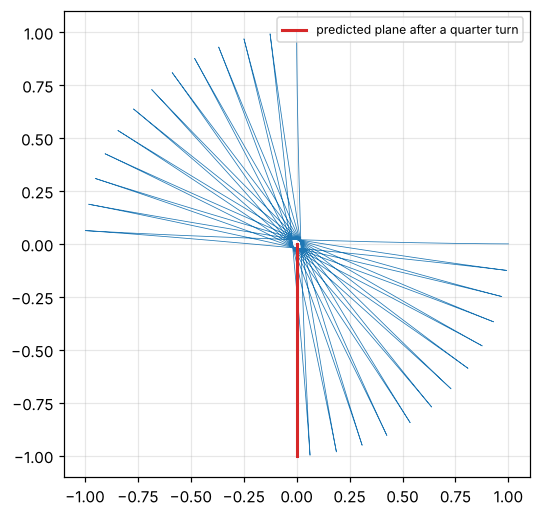

In [5]:
#| label: fig-foucault
#| caption: A Foucault pendulum integrated numerically, with Ω_z exaggerated to 2% of ω₀ so the precession is visible within a few dozen swings. The swing plane rotates clockwise, as predicted.
w0, Oz = 1.0, 0.02
def rhs(s, u):
    x, y, vx, vy = u
    return [vx, vy, -w0**2 * x + 2 * Oz * vy, -w0**2 * y - 2 * Oz * vx]
sol = solve_ivp(rhs, (0, 2 * np.pi / Oz / 4), [1, 0, 0, 0], max_step=0.02, rtol=1e-9)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(sol.y[0], sol.y[1], lw=0.5)
ang = -Oz * sol.t[-1]
ax.plot([0, np.cos(ang)], [0, np.sin(ang)], "tab:red", lw=2, label="predicted plane after a quarter turn")
ax.set_aspect("equal"); ax.legend(fontsize=8, loc="upper right"); plt.show()

### Exercises

1. An object is dropped from a 100 m tower on the equator. How far east of the base does it land?
2. How long does a Foucault pendulum at latitude $30^\circ$ take to turn its swing plane once around?
3. A bucket of water spins at angular velocity $\omega$. Use the effective gravity in the rotating frame to show that the water surface is a paraboloid, $z = \omega^2\rho^2/(2g)$.

:::{dropdown} Hints
1. $t = \sqrt{2h/g}$; use $\Delta x = \tfrac13\Omega gt^3$.
2. $\tau = $ sidereal day $/\sin\lambda$.
3. In the rotating frame the water is at rest, so its surface is perpendicular to $\mathbf{g}_{\text{eff}} = -g\hat{\mathbf{z}} + \omega^2\rho\,\hat{\boldsymbol\rho}$; equivalently it is a surface of constant $gz - \tfrac12\omega^2\rho^2$.
:::

:::{dropdown} Answers
1. $t\approx4.52$ s, so $\Delta x\approx\tfrac13(7.29\times10^{-5})(9.81)(92.1)\approx2.2$ cm.
2. $23.93\ \text{h}/0.5\approx47.9$ h.
3. The surface slope must be $dz/d\rho = \omega^2\rho/g$, so $z = \omega^2\rho^2/2g$ plus a constant.
:::

## Summary

- In a frame accelerating at $\mathbf{A}$, add the fictitious force $-m\mathbf{A}$. Tides are the leftover difference between gravity at a point and at the frame's center.
- Rates of change in rotating and inertial frames differ by $\boldsymbol\Omega\times\mathbf{Q}$. Applying this twice gives the Coriolis force $2m\dot{\mathbf{r}}\times\boldsymbol\Omega$ and the centrifugal force $m(\boldsymbol\Omega\times\mathbf{r})\times\boldsymbol\Omega$.
- On Earth, the centrifugal force is absorbed into $\mathbf{g}_{\text{eff}}$. The Coriolis force deflects horizontal motion by $2\Omega\sin\lambda\,v$ and makes falling objects land slightly east.
- A Foucault pendulum's plane turns at $\Omega\sin\lambda$, which the complex-variable method shows in a few lines.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.